# Microburbs API: your first 10 minutes in Python

This walks through the Microburbs API from a blank page to a table and a chart
covering the nine sandbox suburbs, one per state and territory. Each step is a few
lines you can copy into your own project.

1. Set your key
2. Find a suburb
3. Look up one property: profile, valuation and sale history
4. Build a table of market figures for the nine sample suburbs
5. Chart it
6. Pull a 2021 figure from our area statistics

The same steps live in `quickstart.py` (run it with `python quickstart.py`) and in
`quickstart.ipynb`. API docs: https://www.microburbs.com.au/developers/api-docs

## 1. Set your key

The API needs a key on every request. With no key set, this walk-through uses the
public sandbox key, `test`: free, no sign-up, and limited to nine sample suburbs and
eight sample properties. For the rest of Australia get a key at
https://www.microburbs.com.au/developers/keys and keep it out of your code: put it in an
environment variable called `MICROBURBS_API_KEY`. The easiest way is a `.env` file next to
this script (copy `.env.example` and paste your key in); `load_dotenv()` reads it.

`Microburbs` is the small helper client in `microburbs_client.py`. It adds the key to
each request, unwraps the `{"data": ...}` envelope, and waits and retries if you hit the
rate limit. Copy it into your own project.

In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from matplotlib.ticker import FuncFormatter

from microburbs_client import Microburbs

load_dotenv()  # reads MICROBURBS_API_KEY from .env if you have one
mb = Microburbs()

try:
    show = display  # in Jupyter: render tables nicely
except NameError:
    show = print  # in a plain script: print them
    pd.set_option("display.width", 200, "display.max_columns", 20)

print(mb.get("/v1/ping"))

{'ok': True, 'service': 'microburbs-api', 'version': '1.0.0'}


## 2. Find a suburb

Suburbs are named by their official suburb name (SAL), and some carry a suffix: it's
`St Kilda (Vic.)`, not `St Kilda`, because Queensland and South Australia have one too.
`/v1/geocode/suburb` turns whatever a user typed into the exact name the other endpoints
expect. It is free, and works for every suburb even on the sandbox key.

In [2]:
for match in mb.get("/v1/geocode/suburb", q="st kilda"):
    print(match["area_name"], "|", match["information"]["lga"], "|", match["information"]["poa"])

St Kilda (Qld) | Bundaberg | 4671
St Kilda (SA) | Salisbury | 5110
St Kilda (Vic.) | Port Phillip | 3182
St Kilda East | Port Phillip | 3183
St Kilda West | Port Phillip | 3182
St Agnes (Qld) | Bundaberg | 4671
St Agnes (SA) | Tea Tree Gully | 5097
St Albans (NSW) | Hawkesbury | 2775
St Albans (Vic.) | Brimbank | 3021
St Albans Park | Greater Geelong | 3219


Every property endpoint is keyed by a **GNAF id** (Australia's national address
identifier). With your own key, `/v1/geocode/address` turns an address into one. Address
search is billed, so the sandbox key can't use it; instead it answers for eight documented
sample properties. We use 27 Arlington Street, Belmont North NSW.

In [3]:
gnaf_id = "GANSW704074813"

## 3. One property: profile, valuation and sale history

With a GNAF id you can ask about the property itself. Three useful starting points:

- `/profile`: which suburb, postcode and statistical areas it sits in;
- `/valuation/avm`: an automated estimate of what it's worth today, with a range;
- `/sale-history`: every recorded sale.

In [4]:
profile = mb.get(f"/v1/properties/{gnaf_id}/profile")
print(f"Suburb: {profile['suburb']} {profile['postcode']}  |  LGA: {profile['lga']}")

basics = mb.get(f"/v1/properties/{gnaf_id}/basics/all")
print(f"{basics['dwelling_type']}, {basics['bed_count']} bed, {basics['bath_count']} bath")

avm = mb.get(f"/v1/properties/{gnaf_id}/valuation/avm")
if avm:
    print(
        f"Estimated value: ${avm['predicted_price']:,.0f} "
        f"(range ${avm['predicted_price_low']:,.0f} to ${avm['predicted_price_high']:,.0f}, "
        f"confidence {avm['confidence_score']}/100, as of {avm['prediction_date']})"
    )

sales = mb.get(f"/v1/properties/{gnaf_id}/sale-history") or []
show(pd.DataFrame(sales))

Suburb: Belmont North 2280  |  LGA: Lake Macquarie
house, 2 bed, 1 bath
Estimated value: $767,059 (range $498,588 to $1,035,530, confidence 65/100, as of 2026-07-27)


,date,type,address,price
0,2023-05-01,For Sale,27 Arlington Street,NaN
1,2023-04-26,For Sale,27 Arlington Street,759000.0
2,2022-04-08,Sold,27 Arlington Street,615000.0
3,2012-03-15,Sold,27 Arlington Street,220000.0


## 4. The nine sample suburbs in one table

The sandbox key answers for one sample suburb per state and territory (two in NSW). With
your own key, any list of suburbs works the same way. For each one we fetch five small
market endpoints and keep a handful of figures.

We show **houses** and **units** side by side. Prices are dollars, rents are dollars a
week, and yield and growth come back as fractions (0.045 means 4.5%).

Two things to notice:

- **Be polite.** 9 suburbs × 5 endpoints is 45 requests. We run 4 at a time, well under
  the limit (about 10 a second). The client waits and retries if we ever get a 429.
- **Data can be missing.** Some suburbs have too few sales for a figure, and then the API
  answers `{"data": null, "available": false, ...}`. The client returns `None`, and we
  record a blank rather than crash.

In [5]:
suburbs = [
    "Bondi", "Belmont North", "St Kilda (Vic.)", "Fortitude Valley", "Subiaco",
    "Unley", "Sandy Bay", "Kambah", "Nightcliff",
]
print(len(suburbs), "suburbs:", ", ".join(suburbs))


def market_row(suburb: str) -> dict:
    """A few headline market figures for one suburb. Missing data becomes None."""
    base = f"/v1/suburbs/{suburb}/market"
    price = mb.get(f"{base}/median-sale-price") or {}
    rent = mb.get(f"{base}/median-rent") or {}
    yld = mb.get(f"{base}/yield-pct") or {}
    growth = (mb.get(f"{base}/price-growth") or {}).get("unit") or {}
    sales = mb.get(f"/v1/suburbs/{suburb}/sales/summary") or {}
    return {
        "suburb": suburb,
        "unit_median_price": price.get("unit"),
        "house_median_price": price.get("house"),
        "unit_weekly_rent": rent.get("unit"),
        "unit_gross_yield": yld.get("unit"),
        "house_weekly_rent": rent.get("house"),
        "unit_growth_1y": growth.get("1yr"),
        "unit_growth_5y": growth.get("5yr"),
        "sales_3y": sales.get("sales_count_3y"),  # all dwellings, last 3 years
    }


with ThreadPoolExecutor(max_workers=4) as pool:
    rows = list(pool.map(market_row, suburbs))

df = pd.DataFrame(rows).set_index("suburb").sort_values("unit_median_price", ascending=False)

Path("out").mkdir(exist_ok=True)
df.to_csv("out/sample_suburbs_market.csv")



def fmt(template: str):
    """Formatter for one column: blank where the API had no data."""
    return lambda v: "" if pd.isna(v) else template.format(v)


# A copy formatted for reading: dollars and percentages.
show(
    df.assign(
        unit_median_price=df["unit_median_price"].map(fmt("${:,.0f}")),
        house_median_price=df["house_median_price"].map(fmt("${:,.0f}")),
        unit_weekly_rent=df["unit_weekly_rent"].map(fmt("${:,.0f}")),
        house_weekly_rent=df["house_weekly_rent"].map(fmt("${:,.0f}")),
        unit_gross_yield=df["unit_gross_yield"].map(fmt("{:.1%}")),
        unit_growth_1y=df["unit_growth_1y"].map(fmt("{:+.1%}")),
        unit_growth_5y=df["unit_growth_5y"].map(fmt("{:+.1%}")),
        sales_3y=df["sales_3y"].map(fmt("{:,.0f}")),
    )
)

9 suburbs: Bondi, Belmont North, St Kilda (Vic.), Fortitude Valley, Subiaco, Unley, Sandy Bay, Kambah, Nightcliff


,unit_median_price,house_median_price,unit_weekly_rent,unit_gross_yield,house_weekly_rent,unit_growth_1y,unit_growth_5y,sales_3y
suburb,,,,,,,,
Bondi,"$1,460,000","$3,980,000","$1,000",3.5%,"$1,800",+4.6%,+9.5%,390
Subiaco,"$825,000","$2,280,000",$750,4.7%,"$1,100",+10.1%,+52.8%,559
Unley,"$788,000","$1,710,000",$625,4.1%,$750,+5.3%,+55.0%,170
Belmont North,"$705,000","$1,050,000",$588,3.9%,$675,+6.8%,+51.6%,253
Fortitude Valley,"$700,000","$640,000",$675,5.0%,$662,+17.6%,+54.6%,"1,054"
Sandy Bay,"$664,000","$1,220,000",$525,4.1%,$750,+9.3%,+1.6%,422
Kambah,"$630,000","$925,000",$625,5.2%,$675,-8.7%,+16.5%,466
St Kilda (Vic.),"$515,000","$1,470,000",$575,5.8%,$900,+4.0%,-7.4%,"1,460"
Nightcliff,"$430,000","$1,150,000",$575,7.0%,$750,+15.1%,+11.7%,124


A quick sanity check: which figures are missing, and for how many suburbs?

Also look at `sales_3y`. A median from a few dozen sales jumps around, so check the
sales count before you trust a figure.

In [6]:
print(df.isna().sum().to_string())

unit_median_price     0
house_median_price    0
unit_weekly_rent      0
unit_gross_yield      0
house_weekly_rent     0
unit_growth_1y        0
unit_growth_5y        0
sales_3y              0


## 5. A chart

Median house price for every sample suburb, cheapest at the bottom. Suburbs with fewer
than 100 sales in three years are drawn lighter, because their medians are less reliable.
Plain matplotlib on the DataFrame from step 4; the chart is also saved to
`out/house_prices.png`.

Saved out/house_prices.png


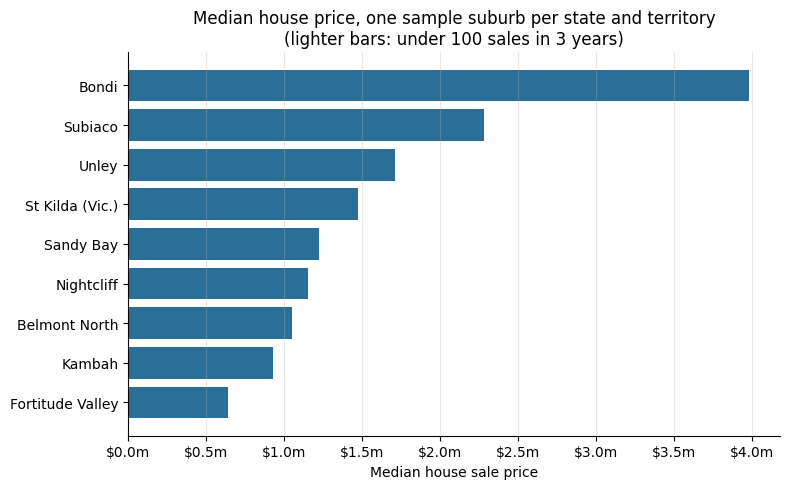

In [7]:
chart = df.dropna(subset=["house_median_price"]).sort_values("house_median_price")
thin = chart["sales_3y"].fillna(0) < 100
colours = ["#a9c9dd" if t else "#2a6f97" for t in thin]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(chart.index, chart["house_median_price"], color=colours)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v / 1e6:.1f}m"))
ax.set_xlabel("Median house sale price")
ax.set_title("Median house price, one sample suburb per state and territory\n(lighter bars: under 100 sales in 3 years)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("out/house_prices.png", dpi=120)
print("Saved out/house_prices.png")

## 6. Our area statistics

`/v1/area-stats` exposes about 17,000 area statistics (mostly from 2021) for suburbs and
other areas. It works in two steps:

1. **Search for a field** with `/v1/area-stats/fields`. Searching is free, on any key.
2. **Fetch values** for a region with `/v1/area-stats/{level}/{region}/values`, passing up to
   5 field codes. `SAL` is the official name for the suburb level.

In [8]:
fields = mb.get("/v1/area-stats/fields", query="median age", limit=5)["fields"]
show(pd.DataFrame(fields)[["field_code", "label", "topic"]])

,field_code,label,topic
0,Median_age_persons,Median age of persons,Selected Medians and Averages
1,Median_mortgage_repay_monthly,Median mortgage repayment ($/monthly),Selected Medians and Averages
2,Median_rent_weekly,Median rent ($/weekly),Selected Medians and Averages
3,Average_household_size,Average household size,Selected Medians and Averages
4,Median_tot_fam_inc_weekly,Median total family income ($/weekly),Selected Medians and Averages


In [9]:
stats = mb.get(
    "/v1/area-stats/SAL/Bondi/values",
    fields="Median_age_persons,Median_rent_weekly,Average_household_size",
)
print(f"{stats['region_name']}, {stats['year']}:")
for f in stats["fields"]:
    print(f"  {f['label']}: {f['value']}")

Bondi, 2021:
  Average household size: 2.1
  Median age of persons: 34.0
  Median rent ($/weekly): 656.0


The 2021 rent is the median across all rented dwellings in 2021. Compare it with the current
median unit rent from step 4 to see how far asking rents have moved since.

In [10]:
rent_2021 = next(f["value"] for f in stats["fields"] if f["field_code"] == "Median_rent_weekly")
today_rent = df.loc["Bondi", "unit_weekly_rent"]
print(f"Bondi weekly rent: ${rent_2021:,.0f} (2021, all dwellings) "
      f"vs ${today_rent:,.0f} (current median unit rent)")

Bondi weekly rent: $656 (2021, all dwellings) vs $1,000 (current median unit rent)


## Where next

- Browse every endpoint at https://www.microburbs.com.au/developers/api-docs. Most suburb
  endpoints take the same `{suburb_name}` you used here, and property endpoints take a GNAF id.
- Get a key at https://www.microburbs.com.au/developers/keys for every suburb and address
  in Australia.
- Need one figure for every suburb? Use the loop in step 4 with a different endpoint.
- Bundles such as `/market/all` or `/valuation/all` return several sections in one call.